In [1]:

import librosa

# Load a built-in example audio file from librosa
# 'y' will be the audio time series (a series of amplitude measurements)
# 'sr' will be the sampling rate
y, sr = librosa.load(librosa.ex('trumpet'))

print("The sampling rate is:", sr, "Hz")
# The audio time series 'y' is a NumPy array. Let's see how many samples it contains.
print("Total number of samples:", len(y))

The sampling rate is: 22050 Hz
Total number of samples: 117601


Here, librosa loaded the trumpet audio by taking 22,050 snapshots (samples) every single second. The entire clip is made up of 117,601 of these individual snapshots.

With these two pieces of information, we can figure out the exact duration of the audio clip.

Duration (in seconds) = Total Samples / Sampling Rate

So for our trumpet clip: 117,601 samples / 22,050 samples per second ≈ 5.33 seconds.

If I want a higher quality audio say of 44,100 samples per second, of the same length 5.33 seconds, I will have a audio of more samples. It is similar to watching a movie with is 30 Hz and something that is sampled at 60 Hz or 120 Hz. You get a smoother experience.

In the case the sampling rate goes down, then we term this as "Aliasing". Audio aliasing is a distortion that happens when an analog audio signal is converted to digital form, causing high-frequency components to appear as lower, unwanted frequencies

Nyquist Theorem - The sampling rate must be at least twice the highest frequency present in the signal.

 librosa's default of 22,050 Hz is a smart compromise; it still captures all the frequencies necessary for most music and speech analysis while keeping the data size manageable.

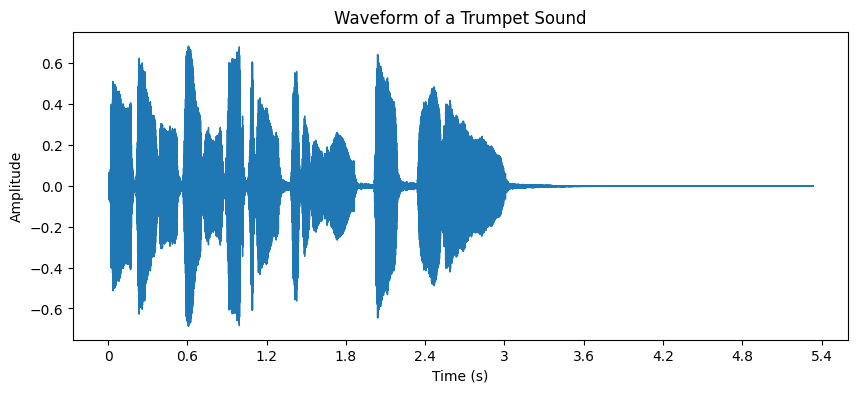

In [2]:
# We need to import matplotlib to plot
import matplotlib.pyplot as plt
# And import librosa's display functions
import librosa.display

# Create a figure and axes for our plot
fig, ax = plt.subplots(figsize=(10, 4))

# Display the waveform
# We pass the audio time series 'y' and the sampling rate 'sr'
librosa.display.waveshow(y, sr=sr, ax=ax)

# Set the title and labels for clarity
ax.set(title='Waveform of a Trumpet Sound', xlabel='Time (s)', ylabel='Amplitude')

# Show the plot
plt.show()

The above figure is the waveform of the trumpet video that we imported earlier plotted with the help of matplotlib and librosa's display function

Comparing high pitch and low piutch notes in audio

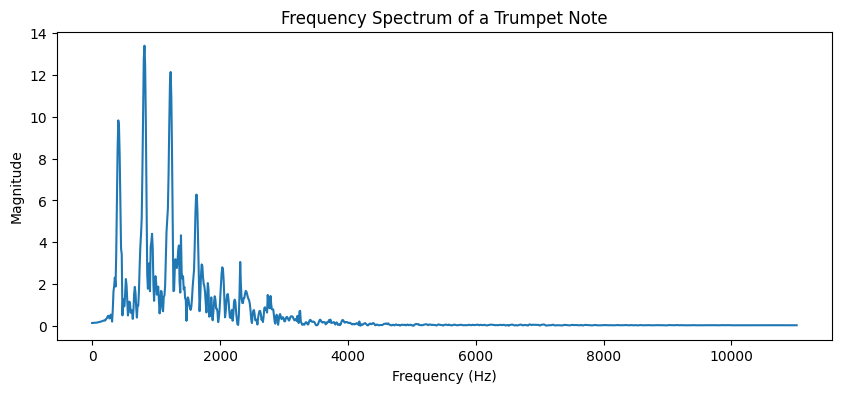

In [3]:
# We'll need numpy and scipy's FFT module
import numpy as np
from scipy.fft import fft

# --- We can reuse our trumpet audio 'y' and 'sr' from before ---

# The FFT is most meaningful on a short segment of audio.
# Let's take a slice of our audio, about 1/10th of a second.
n_samples = 2048 # A common FFT size
start_sample = 50000 # A point where the trumpet is playing clearly
y_segment = y[start_sample : start_sample + n_samples]

# 1. Calculate the FFT
yf = fft(y_segment)
# The output of fft is complex, so we take its absolute value to get the magnitude
yf_magnitude = np.abs(yf)

# 2. Create the frequency axis for the plot
# The FFT gives us magnitudes for a range of frequencies
freq_axis = np.linspace(0, sr, len(yf_magnitude))

# 3. Plot the magnitude spectrum
fig, ax = plt.subplots(figsize=(10, 4))

# We only plot the first half of the output, due to FFT symmetry
half_len = len(yf_magnitude) // 2
ax.plot(freq_axis[:half_len], yf_magnitude[:half_len])

ax.set(title='Frequency Spectrum of a Trumpet Note', xlabel='Frequency (Hz)', ylabel='Magnitude')
plt.show()

You observe that in the above plot the highest peak is at ~ 1000 Hz. This is called the fundamental frequency of that note. It is a representation of the pitch we hear. This ofcourse is based on the 2048 samples that we have considered for the above analysis

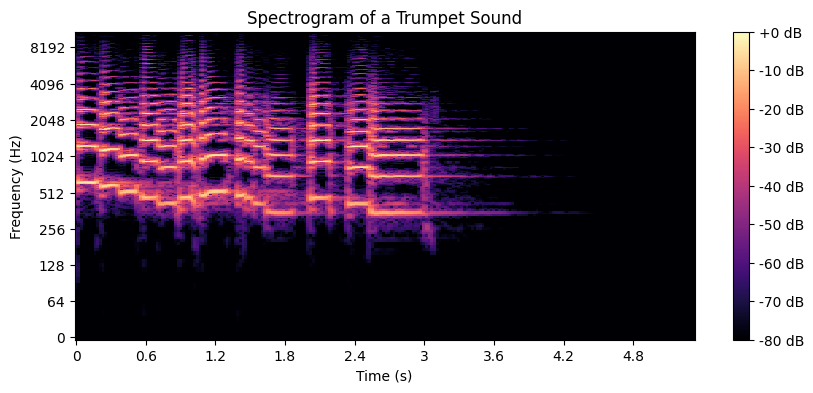

In [4]:
# --- We reuse 'y' and 'sr' from our first step ---

# 1. Calculate the Short-Time Fourier Transform (STFT), which is the basis for the spectrogram
D = librosa.stft(y)

# 2. Convert the complex-valued output to a magnitude spectrogram
# We also convert the amplitude to a decibel (dB) scale, which is often easier to visualize
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# 3. Plot the spectrogram
fig, ax = plt.subplots(figsize=(10, 4))
img = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', ax=ax)
fig.colorbar(img, ax=ax, format='%+2.0f dB')
ax.set(title='Spectrogram of a Trumpet Sound', xlabel='Time (s)', ylabel='Frequency (Hz)')
plt.show()

The bright lines you see in the spectrogram are frequencies at which the pitch is the highest, that is at some ~600 Hz, you have the fundamental frequency, and the other horizontal lines above it, are the different harmonics in the signal